### Homework 4

In [2]:
!curl -o homework4.csv https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  272k  100  272k    0     0  2940k      0 --:--:-- --:--:-- --:--:-- 2958k


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [4]:
df = pd.read_csv("homework4.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [5]:
print(df.shape)
print(df.isnull().sum())
print(df.converted.mean())

(5000, 9)
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64
0.5766


In [6]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['number_of_courses_viewed', 'annual_income', 'interaction_count', 'lead_score']

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

In [7]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [8]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values

In [9]:
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
        print(f'{col:28s} {auc:.4f}  (inverted)')
    else:
        print(f'{col:28s} {auc:.4f}')

number_of_courses_viewed     0.7230
annual_income                0.6082
interaction_count            0.7649
lead_score                   0.7882


##### Q2

In [10]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    return dv, model


def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

In [11]:

dv, model = train(df_train, y_train, C=1.0)
y_pred = predict(df_val, dv, model)

print(round(roc_auc_score(y_val, y_pred), 3))

0.732


#### Q3

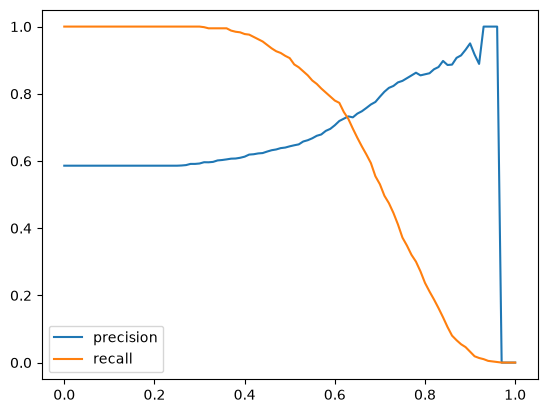

,threshold,tp,fp,fn,precision,recall,diff
63,0.63,425,155,161,0.732759,0.725256,0.007503
62,0.62,437,165,149,0.725914,0.745734,0.019820
64,0.64,408,151,178,0.729875,0.696246,0.033629
61,0.61,453,177,133,0.719048,0.773038,0.053990
65,0.65,392,137,194,0.741021,0.668942,0.072079


In [12]:
thresholds = np.arange(0.0, 1.01, 0.01)
rows = []

for t in thresholds:
    predict_pos = (y_pred >= t)
    actual_pos = (y_val == 1)

    tp = (predict_pos & actual_pos).sum()
    fp = (predict_pos & ~actual_pos).sum()
    fn = (~predict_pos & actual_pos).sum()

    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    rows.append((round(t, 2), tp, fp, fn, p, r))

df_scores = pd.DataFrame(rows, columns=['threshold', 'tp', 'fp', 'fn', 'precision', 'recall'])

plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.legend()
plt.show()

valid = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
valid['diff'] = (valid.precision - valid.recall).abs()
valid.sort_values('diff').head()

#### Q4

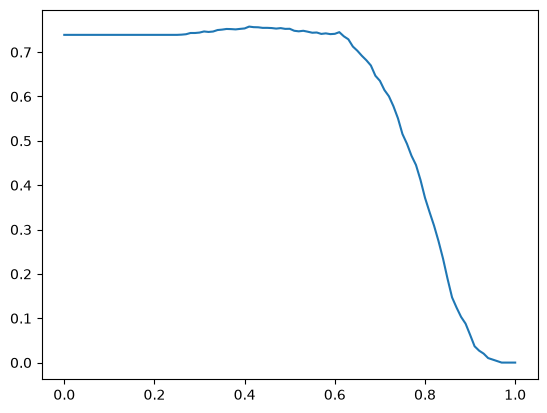

,threshold,tp,fp,fn,precision,recall,f1
41,0.41,572,352,14,0.619048,0.976109,0.757616
42,0.42,568,348,18,0.620087,0.969283,0.756325
43,0.43,564,342,22,0.622517,0.962457,0.756032
45,0.45,554,328,32,0.628118,0.945392,0.754768
44,0.44,560,338,26,0.623608,0.955631,0.754717


In [13]:
p, r = df_scores.precision, df_scores.recall
df_scores['f1'] = np.where((p + r) > 0, 2 * p * r / (p + r), 0.0)

plt.plot(df_scores.threshold, df_scores.f1)
plt.show()

df_scores.sort_values('f1', ascending=False).head()

##### Q5

In [14]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    dv, model = train(df_tr, df_tr.converted.values, C=1.0)
    y_pred_fold = predict(df_va, dv, model)
    scores.append(roc_auc_score(df_va.converted.values, y_pred_fold))

print(np.round(scores, 3))
print('mean = %.3f  std = %.3f' % (np.mean(scores), np.std(scores)))

[0.731 0.73  0.736 0.741 0.721]
mean = 0.732  std = 0.007


##### Q6

In [15]:
results = []

for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        dv, model = train(df_tr, df_tr.converted.values, C=C)
        y_pred_fold = predict(df_va, dv, model)
        scores.append(roc_auc_score(df_va.converted.values, y_pred_fold))

    results.append((C, round(np.mean(scores), 3), round(np.std(scores), 3)))
    print('C=%-9s mean=%.3f  std=%.3f' % (C, np.mean(scores), np.std(scores)))

sorted(results, key=lambda x: (-x[1], x[2], x[0]))[0]

C=1e-06     mean=0.617  std=0.019
C=0.001     mean=0.749  std=0.010
C=1         mean=0.732  std=0.007


(0.001, np.float64(0.749), np.float64(0.01))